In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats
from matplotlib.colors import to_rgba

In [2]:
# load dfs

# tubes
act_tubes = pd.read_parquet('act_tubes.parquet')
OD_tubes = pd.read_parquet('OD_tubes.parquet')

# sf [0]
act_sf_br = pd.read_parquet('act_ALE7_newtryp.parquet')
OD_sf_br = pd.read_parquet('OD_ALE7_newtryp.parquet')

# 700 mL
act_br_0506 = pd.read_parquet('act_ALE7_newtryp_0906.parquet')
OD_br_0506 = pd.read_parquet('OD_ALE7_newtryp_0906.parquet')

# 20L
act_ALE7_20L = pd.read_parquet('../batch runs 20L/act_ALE7_20L.parquet')
OD_ALE7_20L = pd.read_parquet('../batch runs 20L/OD_ALE7_20L.parquet')

In [3]:
# ---------- significance functions ----------

def extract_pool5(dfs, prefix):
    data = {}
    for name, df in dfs.items():
        row = df[df[f"{prefix}_pool"] == 5].iloc[0]
        data[name] = {
            "mean": row[f"{prefix}_mean"],
            "std": row[f"{prefix}_std"],
            "n": row[f"{prefix}_n"],
        }
    return data

# pairwise comparisons
def planned_pairwise_tests(data, pairs, adjust_method="holm"):
    results = []

    for g1, g2 in pairs:
        d1 = data[g1]
        d2 = data[g2]

        t, p = ttest_ind_from_stats(
            mean1=d1["mean"], std1=d1["std"], nobs1=d1["n"],
            mean2=d2["mean"], std2=d2["std"], nobs2=d2["n"],
            equal_var=False
        )

        results.append({
            "group1": g1,
            "group2": g2,
            "p_value": p
        })

    results = pd.DataFrame(results)

    if len(results) > 0:
        _, p_adj, _, _ = multipletests(results["p_value"], method=adjust_method)
        results["p_adj"] = p_adj
        results["stars"] = results["p_adj"].apply(p_to_stars)

    return results

# correct for mutiple testing
def adjust_pvalues(df):
    _, p_adj, _, _ = multipletests(df["p_value"], method="holm")
    df["p_adj"] = p_adj
    return df

# ---------- plotting helpers ----------
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def df_to_bracket_pairs(df, xmap, p_col="p_adj"):
    pairs = []

    for _, row in df.iterrows():
        label = row["stars"] if "stars" in df.columns else p_to_stars(row[p_col])
        if label == "":
            continue

        pairs.append({
            "x1": xmap[row["group1"]],
            "x2": xmap[row["group2"]],
            "label": label,
            "group1": row["group1"],
            "group2": row["group2"],
        })

    return pairs


def add_sig_bracket(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y],
            linewidth=1, color="black")
    ax.text((x1 + x2) / 2, y + h, text,
            ha="center", va="bottom", fontsize=10)

def add_sig_brackets_grouped(ax, bracket_pairs, height_lookup, h=None, bar_gap=None, bracket_gap=None, text_offset=None):
    if not bracket_pairs:
        return

    all_tops = [v for v in height_lookup.values() if not np.isnan(v)]
    ymax = max(all_tops)

    if h is None:
        h = 0.03 * ymax if ymax > 0 else 0.05
    if bar_gap is None:
        bar_gap = 0.05 * ymax
    if bracket_gap is None:
        bracket_gap = 0.03 * ymax
    if text_offset is None:
        text_offset = 0.01 * ymax if ymax > 0 else 0.02

    current_top = ymax

    for i, pair in enumerate(bracket_pairs):
        y = ymax + bar_gap + i * (h + bracket_gap)

        add_sig_bracket(ax, pair["x1"], pair["x2"], y, h, pair["label"])

        current_top = max(current_top, y + h + text_offset)

    ax.set_ylim(top=current_top + bracket_gap)

In [ ]:
# calculate significance
# define comparisons
pairs = [
    ('ALE7_tube', 'ALE7_sf'),
    ('ALE7_tube', 'ALE7_batch'),
    ('ALE7_tube', 'ALE7_20L'),
    ("ALE7_sf", "ALE7_batch"),
    ("ALE7_sf", "ALE7_20L"),
    ("ALE7_batch", "ALE7_20L"),
]


# volumetric activity
# stats dictionary
vol_stats = {
    "ALE7_tube":{"mean": act_tubes['vol_mean'].iloc[1], "std": act_tubes['vol_std'].iloc[1], "n": act_tubes['vol_n'].iloc[1]},
    "ALE7_sf":   {"mean": act_sf_br['vol_mean'].iloc[0],   "std": act_sf_br['vol_std'].iloc[0],   "n": act_sf_br['vol_n'].iloc[0]},
    "ALE7_batch":{"mean": act_br_0506['vol_mean'].iloc[-1], "std": act_br_0506['vol_std'].iloc[-1], "n": act_br_0506['vol_n'].iloc[-1]},
    "ALE7_20L":{"mean": act_ALE7_20L['vol_mean'].iloc[-1], "std": act_ALE7_20L['vol_std'].iloc[-1], "n": act_ALE7_20L['vol_n'].iloc[-1]},
}

# normalized activity
# stats dictionary
norm_stats = {
    "ALE7_tube":{"mean": act_tubes['norm_mean'].iloc[1], "std": act_tubes['norm_std'].iloc[1], "n": act_tubes['norm_n'].iloc[1]},
    "ALE7_sf":   {"mean": act_sf_br['norm_mean'].iloc[0],   "std": act_sf_br['norm_std'].iloc[0],   "n": act_sf_br['norm_n'].iloc[0]},
    "ALE7_batch":{"mean": act_br_0506['norm_mean'].iloc[-1], "std": act_br_0506['norm_std'].iloc[-1], "n": act_br_0506['norm_n'].iloc[-1]},
    "ALE7_20L":   {"mean": act_ALE7_20L['norm_mean'].iloc[-1],   "std": act_ALE7_20L['norm_std'].iloc[-1],   "n": act_ALE7_20L['norm_n'].iloc[-1]},
}

# OD
# stats dictionary
od_stats = {
    "ALE7_tube":{"mean": OD_tubes['mean_OD'].iloc[1], "std": OD_tubes['std_OD'].iloc[1], "n": 3},
    "ALE7_sf":   {"mean": OD_sf_br['mean_OD'].iloc[0],   "std": OD_sf_br['std_OD'].iloc[0],   "n": 3},
    "ALE7_batch":{"mean": OD_br_0506['mean_OD'].iloc[-1], "std": OD_br_0506['std_OD'].iloc[-1], "n": 3},
    "ALE7_20L":   {"mean": OD_ALE7_20L['mean_OD'].iloc[-1],   "std": OD_ALE7_20L['std_OD'].iloc[-1],   "n": 3},
}

# run test
vol_results = planned_pairwise_tests(vol_stats, pairs, adjust_method="holm")
norm_results = planned_pairwise_tests(norm_stats, pairs, adjust_method="holm")
od_results = planned_pairwise_tests(od_stats, pairs, adjust_method="holm")

# print results
print(vol_results)
print(norm_results)
print(od_results)

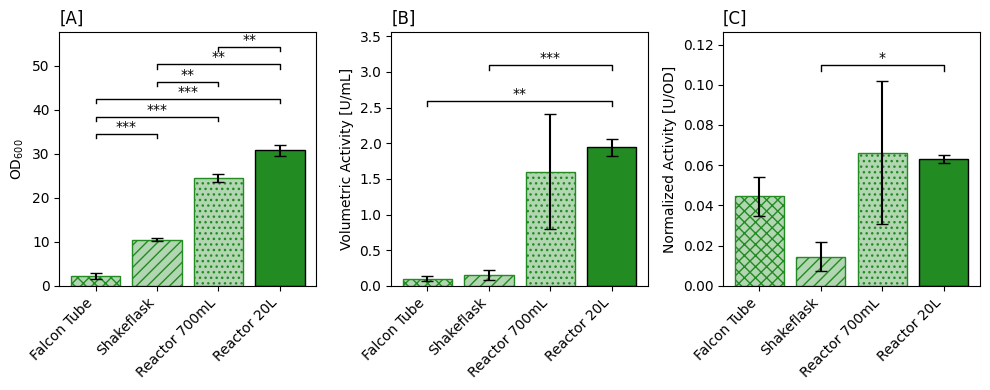

In [ ]:
# PLOTS

groups = ['Falcon Tube', "Shakeflask", "Reactor 700mL", "Reactor 20L"]
keys = ['ALE7_tube', "ALE7_sf", "ALE7_batch", "ALE7_20L"]
colors = ["forestgreen", "forestgreen", "forestgreen", "forestgreen"]

xpos = np.arange(len(groups))
width = 0.6

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

ax_A = axs[0]   # volumetric
ax_B = axs[1]   # normalized
ax_C = axs[2]   # OD

def plot_endpoint(ax, stats, ylabel, title):
    means = [stats[k]["mean"] for k in keys]
    stds = [stats[k]["std"] for k in keys]

    for i, (mean, std, color, key) in enumerate(zip(means, stds, colors, keys)):

        # Falcon tube → solid with different edge, or no hatch
        if key == "ALE7_tube":
            ax.bar(
                xpos[i],
                mean,
                yerr=std,
                capsize=4,
                facecolor=to_rgba(color, 0.35),
                edgecolor=color,
                hatch="xxx",
                linewidth=1.0,
            )
    
        # Shakeflask → diagonal hatch + transparent
        elif key == "ALE7_sf":
            ax.bar(
                xpos[i],
                mean,
                yerr=std,
                capsize=4,
                facecolor=to_rgba(color, 0.35),
                edgecolor=color,
                hatch="///",
                linewidth=1.0,
            )
    
        # 700 mL → solid
        elif key == "ALE7_batch":
            ax.bar(
                xpos[i],
                mean,
                yerr=std,
                capsize=4,
                facecolor=to_rgba(color, 0.35),
                edgecolor=color,
                hatch="...",
                linewidth=1.0,
            )
    
        # 20L → dotted hatch + transparent
        elif key == "ALE7_20L":
            ax.bar(
                xpos[i],
                mean,
                yerr=std,
                capsize=4,
                color=color,
                edgecolor="black",
                linewidth=1.0,
            )
    
    ax.set_xticks(xpos)
    ax.set_xticklabels(groups, rotation=45, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.set_ylim(bottom=0)

# ---------------- A: OD endpoint ----------------
plot_endpoint(
    ax_A,
    od_stats,
    ylabel="OD$_{600}$",
    title="[A]"
)

# ---------------- B: volumetric endpoint ----------------
plot_endpoint(
    ax_B,
    vol_stats,
    ylabel="Volumetric Activity [U/mL]",
    title="[B]"
)

# ---------------- C: normalized endpoint ----------------
plot_endpoint(
    ax_C,
    norm_stats,
    ylabel="Normalized Activity [U/OD]",
    title="[C]"
)

# ---------------- significance brackets ----------------
xmap = dict(zip(keys, xpos))

height_lookup_vol = {
    k: v["mean"] + v["std"]
    for k, v in vol_stats.items()
}

height_lookup_norm = {
    k: v["mean"] + v["std"]
    for k, v in norm_stats.items()
}

height_lookup_od = {
    k: v["mean"] + v["std"]
    for k, v in od_stats.items()
}

bracket_pairs_A = df_to_bracket_pairs(od_results, xmap)
bracket_pairs_B = df_to_bracket_pairs(vol_results, xmap)
bracket_pairs_C = df_to_bracket_pairs(norm_results, xmap)

add_sig_brackets_grouped(ax_A, bracket_pairs_A, height_lookup_od, bracket_gap=3)
add_sig_brackets_grouped(ax_B, bracket_pairs_B, height_lookup_vol, bracket_gap=0.43)
add_sig_brackets_grouped(ax_C, bracket_pairs_C, height_lookup_norm, bracket_gap=0.015)

plt.tight_layout()

#plt.savefig("ALE7_newtryptone_all.png", dpi=300, bbox_inches="tight")
plt.show()